# 03_scalability: centering test + brute-force vs SimHash LSH from 1M to 25M

CO5135 Big Data mini-project (Phase 4).

**Input:** output of notebook `00_prepare_data` (Add Input > Your Work > `00_prepare_data`).

**Part A (1M): does centering help LSH?**
ALS item vectors (no bias term) may share a large common direction, so many unrelated movies have high
cosine and collide in LSH buckets. Test: subtract the mean item vector before L2-normalizing
(adjusted cosine). Compare, for both variants, the cosine distribution, the SimHash trade-off
(recall vs candidate pairs) and Precision@10 of item-based recommendation. Pick the variant and
two SimHash configs for Part B automatically.

**Part B (1M, 5M, 10M, 25M): scalability.**
For each subset: ALS (rank 40, regParam 0.1), movies with >= 20 ratings in train, exact top-20 with
NumPy (single machine) and Spark brute-force, and SimHash banding (Spark) with the 2 chosen configs.
Measure time, candidate pairs, Recall@10.

**Output (in `results/`):** `centering_1m.csv`, `centering_cosine_1m.png`, `centering_tradeoff_1m.png`,
`scalability.csv`, `scalability_time.png`, `scalability_recall.png`, `summary_scalability.json`.

Run with **Save Version > Save & Run All** (runs in the background, about 45 to 75 minutes).

In [1]:
# ===== SETUP =====
import os, glob, time, json, shutil
!pip install -q pyspark

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from pyspark.sql import SparkSession, Window, functions as F
from pyspark.ml.recommendation import ALS
from pyspark.ml.evaluation import RegressionEvaluator

spark = (SparkSession.builder.master("local[*]")
         .config("spark.driver.memory", "20g")
         .config("spark.sql.shuffle.partitions", "32")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

# ----- Tham so (chot tu Phase 3, 23/11) -----
SUBSETS = ["1m", "5m", "10m", "25m"]
RANK, REG, ALS_ITER = 40, 0.1, 10      # ALS tot nhat o 1M
MIN_RATINGS = 20                       # chi tim lang gieng trong phim co >= 20 rating trong train
K, K_NB, LIKE, SEED = 10, 20, 4.0, 42
SH_GRID_R = [4, 6, 8, 10, 12, 14, 16]        # Part A: grid SimHash (tinh bang NumPy)
SH_GRID_B = [10, 20, 40, 80]
MAX_BF_PAIRS = 6e8                     # bo qua Spark brute-force neu so cap qua lon (de khong chay qua lau)

hits = sorted(glob.glob("/kaggle/input/**/data/1m/train", recursive=True)) or sorted(glob.glob("data/1m/train"))
assert hits, "Khong thay du lieu. Kiem tra da Add Input output cua 00_prepare_data chua."
DATA = os.path.dirname(os.path.dirname(hits[0]))
os.makedirs("results", exist_ok=True)
os.makedirs("work", exist_ok=True)
print("DATA:", DATA)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/23 10:10:00 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


DATA: /kaggle/input/notebooks/minhphamcompcsc/00-prepare-data/data


In [2]:
# ===== Style bieu do (giong 01, 02) =====
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e6e5e0", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlecolor": INK, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
})
def save(fig, name):
    fig.savefig(f"results/{name}.png"); print("Saved", f"results/{name}.png")

In [3]:
# ===== Ham dung chung =====
def load(subset):
    tr = spark.read.parquet(f"{DATA}/{subset}/train").cache()
    te = spark.read.parquet(f"{DATA}/{subset}/test").cache()
    return tr, te

def fit_als(train):
    als = ALS(userCol="userId", itemCol="movieId", ratingCol="rating", rank=RANK, regParam=REG,
              maxIter=ALS_ITER, coldStartStrategy="drop", seed=SEED)
    t0 = time.time(); m = als.fit(train); return m, time.time() - t0

def item_matrix(model, train):
    """Raw ALS factors (n x RANK) of movies with >= MIN_RATINGS ratings in train."""
    keep = train.groupBy("movieId").count().filter(F.col("count") >= MIN_RATINGS) \
                .select(F.col("movieId").alias("id"))
    pdf = model.itemFactors.join(keep, "id").orderBy("id").toPandas()
    return pdf["id"].to_numpy(), np.vstack(pdf["features"].to_numpy()).astype(np.float32)

def unit(X, center):
    Y = X - X.mean(axis=0, keepdims=True) if center else X.copy()
    return (Y / np.linalg.norm(Y, axis=1, keepdims=True)).astype(np.float32)

def numpy_topk(X, k=K_NB, block=2048):
    """Exact top-k neighbors by cosine (rows of X are unit vectors), in row blocks to save RAM."""
    n = len(X); out = np.empty((n, k), dtype=np.int64)
    for i0 in range(0, n, block):
        S = X[i0:i0 + block] @ X.T
        S[np.arange(S.shape[0]), np.arange(i0, i0 + S.shape[0])] = -np.inf
        part = np.argpartition(-S, k, axis=1)[:, :k]
        order = np.argsort(-np.take_along_axis(S, part, axis=1), axis=1)
        out[i0:i0 + S.shape[0]] = np.take_along_axis(part, order, axis=1)
    return out

def simhash_keys(X, r, n_bands, seed=SEED):
    H = np.random.default_rng(seed).standard_normal((X.shape[1], r * n_bands)).astype(np.float32)
    bits = (X @ H > 0).astype(np.int64).reshape(len(X), n_bands, r)
    return (bits << np.arange(r)).sum(axis=2)                    # n x n_bands

def banding_stats(X, top_idx, r, n_bands, block=256):
    """NumPy simulation of SimHash banding: Recall@K vs exact and fraction of pairs that collide."""
    keys = simhash_keys(X, r, n_bands)
    nb = top_idx[:, :K]
    recall = (keys[:, None, :] == keys[nb]).any(axis=2).mean()
    n, cand = len(X), 0
    for i0 in range(0, n, block):
        cand += (keys[i0:i0 + block, None, :] == keys[None, :, :]).any(axis=2).sum()
    return float(recall), float((cand - n) / (n * (n - 1)))

def to_spark(ids, X):
    return spark.createDataFrame(pd.DataFrame({"id": ids.astype(int), "arr": X.astype(float).tolist()})) \
                .repartition(16).cache()

DOT = "aggregate(zip_with(fa, fb, (x, y) -> x * y), 0D, (acc, v) -> acc + v)"

def topk(pairs):
    w = Window.partitionBy("a").orderBy(F.desc("sim"), "b")
    return pairs.withColumn("rk", F.row_number().over(w)).filter(F.col("rk") <= K_NB)

def spark_bf(items, path):
    A = items.select(F.col("id").alias("a"), F.col("arr").alias("fa"))
    B = items.select(F.col("id").alias("b"), F.col("arr").alias("fb"))
    t0 = time.time()
    topk(A.crossJoin(B).filter("a != b").withColumn("sim", F.expr(DOT)).select("a", "b", "sim")) \
        .write.mode("overwrite").parquet(path)
    return time.time() - t0

def spark_simhash(items, ids, X, r, n_bands, path):
    A = items.select(F.col("id").alias("a"), F.col("arr").alias("fa"))
    B = items.select(F.col("id").alias("b"), F.col("arr").alias("fb"))
    t0 = time.time()
    keys = simhash_keys(X, r, n_bands)
    bk = spark.createDataFrame(pd.DataFrame({
        "id": np.repeat(ids, n_bands).astype(int),
        "band": np.tile(np.arange(n_bands), len(ids)).astype(int),
        "key": keys.ravel().astype(int)})).cache()
    cand = (bk.alias("x").join(bk.alias("y"), ["band", "key"])
            .select(F.col("x.id").alias("a"), F.col("y.id").alias("b")).filter("a != b").distinct()
            .join(A, "a").join(B, "b").withColumn("sim", F.expr(DOT)).select("a", "b", "sim").cache())
    topk(cand).write.mode("overwrite").parquet(path)
    t = time.time() - t0
    n_cand = cand.count()
    cand.unpersist(); bk.unpersist()
    return t, n_cand

def recall_vs_exact(path, ids, top_idx, k=K):
    exact = {ids[i]: set(ids[top_idx[i, :k]]) for i in range(len(ids))}
    nb = spark.read.parquet(path).filter(F.col("rk") <= k).select("a", "b").toPandas()
    got = nb.groupby("a")["b"].apply(set).to_dict()
    return float(np.mean([len(got.get(i, set()) & exact[i]) / k for i in ids]))

## Part A. Centering test on 1M

In [4]:
train, test = load("1m")
als_model, als_s = fit_als(train)
ids, X_raw = item_matrix(als_model, train)
n = len(ids)
mean_norm = np.linalg.norm(X_raw.mean(axis=0)) / np.linalg.norm(X_raw, axis=1).mean()
print(f"ALS 1M: {als_s:.1f}s | movies used: {n:,} | |mean vector| / mean |vector| = {mean_norm:.2f}")

variants = {"plain": unit(X_raw, center=False), "centered": unit(X_raw, center=True)}
tops = {v: numpy_topk(Xv) for v, Xv in variants.items()}

# Phan phoi cosine: cap ngau nhien vs cap (phim, lang gieng top-10)
rng = np.random.default_rng(SEED)
ia, ib = rng.integers(0, n, 200_000), rng.integers(0, n, 200_000)
ok = ia != ib
cos = {}
for v, Xv in variants.items():
    rand_cos = (Xv[ia[ok]] * Xv[ib[ok]]).sum(axis=1)
    nb_cos = (Xv[:, None, :] * Xv[tops[v][:, :K]]).sum(axis=2).ravel()
    cos[v] = (rand_cos, nb_cos)
    print(f"{v:9s} cosine: random pairs mean {rand_cos.mean():.3f} | top-{K} neighbors mean {nb_cos.mean():.3f}")

ALS 1M: 27.6s | movies used: 4,885 | |mean vector| / mean |vector| = 0.81
plain     cosine: random pairs mean 0.650 | top-10 neighbors mean 0.877
centered  cosine: random pairs mean 0.002 | top-10 neighbors mean 0.627


In [5]:
rows = []
for v, Xv in variants.items():
    for r in SH_GRID_R:
        for b in SH_GRID_B:
            rec, frac = banding_stats(Xv, tops[v], r, b)
            rows.append({"variant": v, "bits_per_band": r, "bands": b,
                         "recall@10": round(rec, 4), "cand_pct": round(100 * frac, 2)})
cent = pd.DataFrame(rows)

def pick_configs(d):
    """Config with fewest candidates at Recall >= 0.9, and at Recall >= 0.95."""
    out = []
    for target in [0.9, 0.95]:
        ok = d[d["recall@10"] >= target]
        if len(ok):
            out.append(ok.sort_values(["cand_pct", "recall@10"], ascending=[True, False]).iloc[0])
    return out

best = {v: pick_configs(cent[cent["variant"] == v]) for v in variants}
for v in variants:
    for p in best[v]:
        print(f"{v:9s}: r={int(p['bits_per_band'])}, B={int(p['bands'])} -> recall {p['recall@10']}, "
              f"candidates {p['cand_pct']}%")

plain    : r=16, B=80 -> recall 0.9544, candidates 39.27%
plain    : r=16, B=80 -> recall 0.9544, candidates 39.27%
centered : r=10, B=80 -> recall 0.9076, candidates 15.01%
centered : r=8, B=80 -> recall 0.9896, candidates 33.84%


In [6]:
# Precision@10 cua goi y item-based dung lang gieng chinh xac cua tung bien the
keep_b = spark.createDataFrame(pd.DataFrame({"b": ids.astype(int)}))
liked = train.filter(F.col("rating") >= LIKE).select("userId", F.col("movieId").alias("a"))
seen = train.select("userId", F.col("movieId").alias("b"))
relevant = (test.filter(F.col("rating") >= LIKE).select("userId", F.col("movieId").alias("b"))
            .join(keep_b, "b").cache())
eval_users = relevant.select("userId").distinct().cache()
liked_eval = liked.join(eval_users, "userId").cache()

def precision_from_top(Xv, top_idx):
    sims = (Xv[:, None, :] * Xv[top_idx]).sum(axis=2)
    nb = spark.createDataFrame(pd.DataFrame({
        "a": np.repeat(ids, K_NB).astype(int), "b": ids[top_idx].ravel().astype(int),
        "sim": sims.ravel().astype(float)}))
    scores = (liked_eval.join(nb, "a").groupBy("userId", "b").agg(F.sum("sim").alias("score"))
              .join(seen, ["userId", "b"], "left_anti"))
    w = Window.partitionBy("userId").orderBy(F.desc("score"), "b")
    recs = scores.withColumn("rk", F.row_number().over(w)).filter(F.col("rk") <= K)
    hits = recs.join(relevant, ["userId", "b"]).groupBy("userId").agg(F.count("*").alias("hits"))
    return eval_users.join(hits, "userId", "left").fillna(0).agg(F.avg(F.col("hits") / K)).first()[0]

prec = {v: round(precision_from_top(variants[v], tops[v]), 4) for v in variants}
overlap = np.mean([len(set(tops["plain"][i, :K]) & set(tops["centered"][i, :K])) / K for i in range(n)])
print(f"Precision@{K} (brute-force neighbors): plain {prec['plain']} | centered {prec['centered']}")
print(f"Overlap of top-{K} neighbor lists, plain vs centered: {overlap:.2%}")

# Chon bien the: centered neu so cap ung vien (o recall >= 0.9) giam it nhat 20% va precision khong giam qua 0.005
cand_at_90 = {v: (best[v][0]["cand_pct"] if best[v] else 100.0) for v in variants}
use_center = (cand_at_90["centered"] <= 0.8 * cand_at_90["plain"]) and (prec["centered"] >= prec["plain"] - 0.005)
VARIANT = "centered" if use_center else "plain"
CONFIGS = [(int(p["bits_per_band"]), int(p["bands"])) for p in best[VARIANT]] or [(12, 20), (10, 20)]
CONFIGS = list(dict.fromkeys(CONFIGS))
print(f"\n==> Part B uses VARIANT = {VARIANT}, SimHash configs (r, B) = {CONFIGS}")

cent["precision@10_bf"] = cent["variant"].map(prec)
cent.to_csv("results/centering_1m.csv", index=False)

Precision@10 (brute-force neighbors): plain 0.0837 | centered 0.1213
Overlap of top-10 neighbor lists, plain vs centered: 57.83%

==> Part B uses VARIANT = centered, SimHash configs (r, B) = [(10, 80), (8, 80)]


Saved results/centering_cosine_1m.png


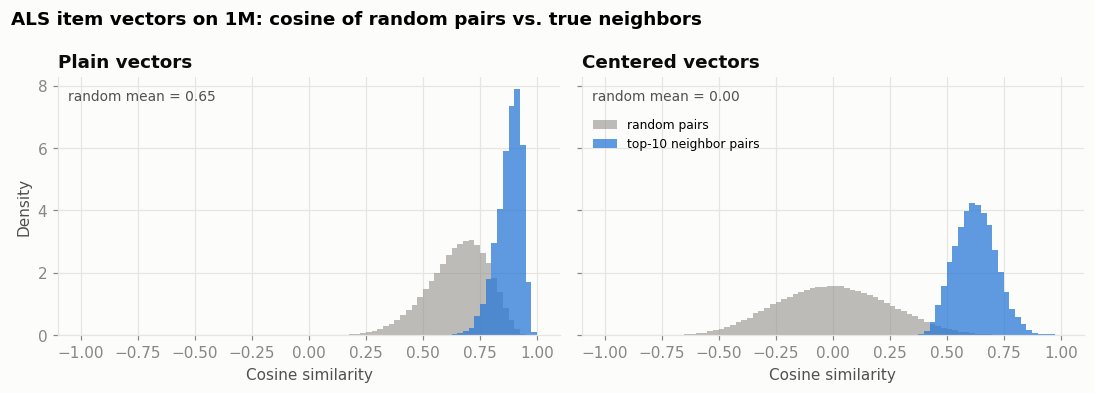

Saved results/centering_tradeoff_1m.png


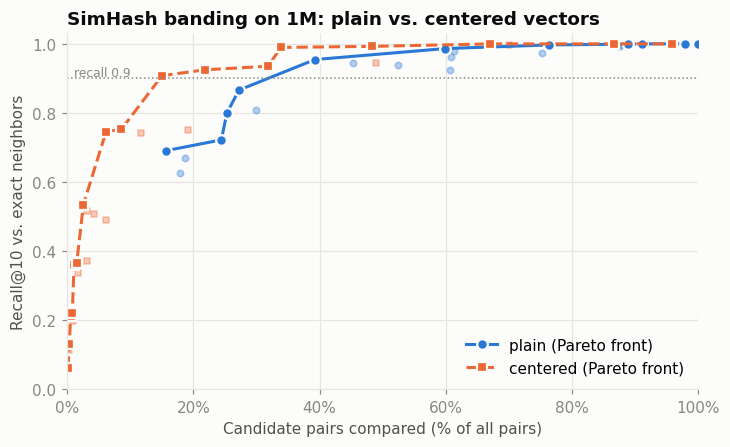

cand_pct         recall@10        
variant             centered   plain  centered   plain
bits_per_band bands                                   
4             10       49.00   87.55    0.9449  0.9923
              20       69.97   99.66    0.9954  1.0000
              40       86.63  100.00    1.0000  1.0000
              80       95.89  100.00    1.0000  1.0000
6             10       19.09   75.28    0.7501  0.9744
              20       31.87   91.58    0.9351  0.9990
              40       48.28   99.59    0.9926  1.0000
              80       66.96   99.91    0.9997  1.0000
8             10        6.07   60.73    0.4885  0.9255
              20       11.75   87.31    0.7424  0.9949
              40       21.84   88.90    0.9248  0.9990
              80       33.84   97.89    0.9896  1.0000
10            10        3.09   29.90    0.3710  0.8081
              20        4.30   60.84    0.5059  0.9625
              40        8.58   76.40    0.7525  0.9942
              80       15.01   91.08    0.9076  0.9998
12            10        0.90   24.42    0.1971  0.7218
              20        1.72   52.36    0.3350  0.9385
              40        3.17   61.27    0.5165  0.9800
              80        6.16   76.39    0.7461  0.9968
14            10        0.35   18.62    0.1147  0.6684
              20        0.80   25.31    0.2192  0.7999
              40        1.50   45.34    0.3655  0.9431
              80        2.55   59.86    0.5338  0.9862
16            10        0.13   17.83    0.0623  0.6264
              20        0.33   15.61    0.1314  0.6905
              40        0.53   27.22    0.2125  0.8661
              80        1.07   39.27    0.3584  0.9544

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
bins = np.linspace(-1, 1, 81)
for ax, v in zip(axes, ["plain", "centered"]):
    rand_cos, nb_cos = cos[v]
    ax.hist(rand_cos, bins=bins, density=True, color=MUTED, alpha=0.55, label="random pairs")
    ax.hist(nb_cos, bins=bins, density=True, color=BLUE, alpha=0.75, label=f"top-{K} neighbor pairs")
    ax.set_title(f"{v.capitalize()} vectors")
    ax.set_xlabel("Cosine similarity")
    ax.text(0.02, 0.95, f"random mean = {rand_cos.mean():.2f}", transform=ax.transAxes, va="top", color=INK2, fontsize=9)
axes[0].set_ylabel("Density")
axes[1].legend(frameon=False, loc="upper left", bbox_to_anchor=(0.0, 0.88), fontsize=8)
fig.suptitle("ALS item vectors on 1M: cosine of random pairs vs. true neighbors", x=0.01, ha="left",
             fontweight="bold", fontsize=12)
fig.tight_layout()
save(fig, "centering_cosine_1m"); plt.show()

fig, ax = plt.subplots(figsize=(7.4, 4.2))
for v, color, ls, mk in [("plain", BLUE, "-", "o"), ("centered", ORANGE, "--", "s")]:
    d = cent[cent["variant"] == v].sort_values("cand_pct")
    front = d[d["recall@10"] == d["recall@10"].cummax()]          # duong Pareto
    ax.scatter(d["cand_pct"], d["recall@10"], color=color, s=18, alpha=0.35, marker=mk)
    ax.plot(front["cand_pct"], front["recall@10"], color=color, linestyle=ls, linewidth=2, marker=mk,
            markersize=7, markeredgecolor=SURFACE, markeredgewidth=1.5, label=f"{v} (Pareto front)")
ax.axhline(0.9, color=MUTED, linewidth=1, linestyle=":")
ax.text(1, 0.905, "recall 0.9", color=MUTED, fontsize=8)
ax.set_title("SimHash banding on 1M: plain vs. centered vectors")
ax.set_xlabel("Candidate pairs compared (% of all pairs)")
ax.set_ylabel(f"Recall@{K} vs. exact neighbors")
ax.set_xlim(0, 100); ax.set_ylim(0, 1.03)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.legend(frameon=False, loc="lower right")
save(fig, "centering_tradeoff_1m"); plt.show()

train.unpersist(); test.unpersist()
cent.pivot_table(index=["bits_per_band", "bands"], columns="variant", values=["recall@10", "cand_pct"])

## Part B. Scalability: 1M, 5M, 10M, 25M

In [8]:
ev = RegressionEvaluator(metricName="rmse", labelCol="rating", predictionCol="prediction")
scal = []
for s in SUBSETS:
    print(f"\n===== {s} =====")
    train, test = load(s)
    n_ratings = train.count() + test.count()
    model, als_s = fit_als(train)
    rmse = ev.evaluate(model.transform(test))
    ids_s, Xr = item_matrix(model, train)
    Xs = unit(Xr, center=(VARIANT == "centered"))
    n_s = len(ids_s); pairs = n_s * (n_s - 1)
    print(f"ALS {als_s:.1f}s, test RMSE {rmse:.4f} | movies used {n_s:,} | pairs {pairs:,}")

    t0 = time.time(); top_s = numpy_topk(Xs); np_s = time.time() - t0
    print(f"NumPy exact: {np_s:.2f}s")
    row = {"subset": s, "ratings": n_ratings, "movies_used": n_s, "pairs": pairs,
           "als_fit_s": round(als_s, 1), "test_rmse": round(rmse, 4), "numpy_s": round(np_s, 2)}

    items = to_spark(ids_s, Xs); items.count()
    if pairs <= MAX_BF_PAIRS:
        bf_s = spark_bf(items, f"work/bf_{s}")
        row["spark_bf_s"] = round(bf_s, 1)
        print(f"Spark brute-force: {bf_s:.1f}s")
    else:
        row["spark_bf_s"] = None
        print("Spark brute-force skipped (too many pairs)")

    for r, b in CONFIGS:
        t, n_cand = spark_simhash(items, ids_s, Xs, r, b, f"work/sh_{s}_r{r}_B{b}")
        rec = recall_vs_exact(f"work/sh_{s}_r{r}_B{b}", ids_s, top_s)
        tag = f"sh_r{r}_B{b}"
        row.update({f"{tag}_s": round(t, 1), f"{tag}_cand_pct": round(100 * n_cand / pairs, 2),
                    f"{tag}_recall": round(rec, 4),
                    f"{tag}_speedup": round(row["spark_bf_s"] / t, 2) if row["spark_bf_s"] else None})
        print(f"SimHash r={r}, B={b}: {t:.1f}s, candidates {100 * n_cand / pairs:.1f}%, recall {rec:.4f}")

    scal.append(row)
    pd.DataFrame(scal).to_csv("results/scalability.csv", index=False)   # luu sau moi tap
    items.unpersist(); train.unpersist(); test.unpersist()
    shutil.rmtree("work", ignore_errors=True); os.makedirs("work", exist_ok=True)

scal_df = pd.DataFrame(scal)
pd.set_option("display.max_columns", None)
scal_df


===== 1m =====


ALS 18.5s, test RMSE 0.8237 | movies used 4,885 | pairs 23,858,340
NumPy exact: 0.35s


Spark brute-force: 65.8s


SimHash r=10, B=80: 31.2s, candidates 15.0%, recall 0.9076


SimHash r=8, B=80: 38.8s, candidates 33.8%, recall 0.9896

===== 5m =====


ALS 59.7s, test RMSE 0.8158 | movies used 9,610 | pairs 92,342,490
NumPy exact: 1.04s


... (8 outputs left out)

Spark brute-force: 881.4s


SimHash r=10, B=80: 279.0s, candidates 19.9%, recall 0.9965


SimHash r=8, B=80: 549.3s, candidates 37.4%, recall 0.9998


,subset,ratings,movies_used,pairs,als_fit_s,test_rmse,numpy_s,spark_bf_s,sh_r10_B80_s,sh_r10_B80_cand_pct,sh_r10_B80_recall,sh_r10_B80_speedup,sh_r8_B80_s,sh_r8_B80_cand_pct,sh_r8_B80_recall,sh_r8_B80_speedup
0,1m,999935,4885,23858340,18.5,0.8237,0.35,65.8,31.2,15.01,0.9076,2.11,38.8,33.84,0.9896,1.69
1,5m,4999764,9610,92342490,59.7,0.8158,1.04,276.5,88.6,18.42,0.9826,3.12,155.2,36.09,0.9983,1.78
2,10m,9999663,12272,150589712,112.6,0.8116,1.61,460.0,139.4,19.19,0.9916,3.30,253.4,37.16,0.9994,1.82
3,25m,25000095,17017,289561272,250.6,0.8070,3.00,881.4,279.0,19.85,0.9965,3.16,549.3,37.40,0.9998,1.60


Saved results/scalability_time.png


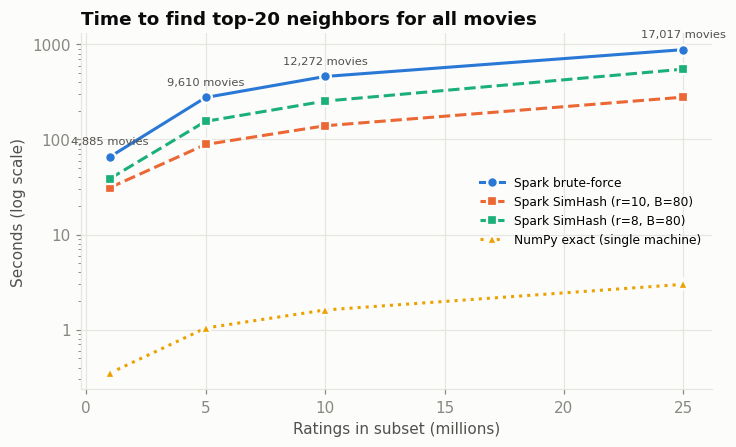

Saved results/scalability_recall.png


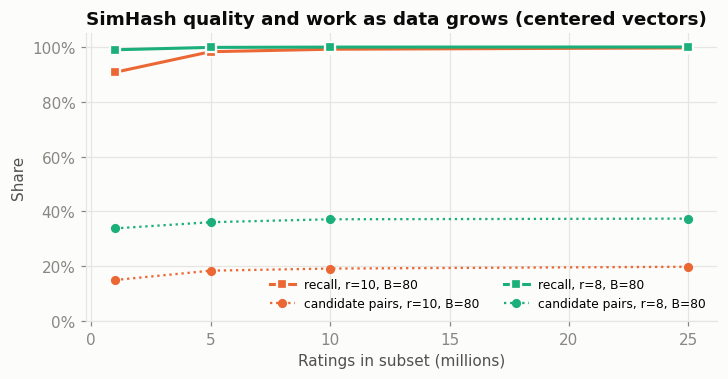

In [9]:
x = scal_df["ratings"] / 1e6
fig, ax = plt.subplots(figsize=(7.4, 4.2))
series = [("spark_bf_s", "Spark brute-force", BLUE, "-", "o")]
series += [(f"sh_r{r}_B{b}_s", f"Spark SimHash (r={r}, B={b})", c, "--", "s")
           for (r, b), c in zip(CONFIGS, [ORANGE, AQUA])]
series += [("numpy_s", "NumPy exact (single machine)", YELLOW, ":", "^")]
for col, label, color, ls, mk in series:
    ax.plot(x, scal_df[col].astype(float).clip(lower=0.01), color=color, linestyle=ls, linewidth=2, marker=mk, markersize=7,
            markeredgecolor=SURFACE, markeredgewidth=1.5, label=label)
for _, r_ in scal_df.iterrows():
    ax.annotate(f"{int(r_['movies_used']):,} movies", (r_["ratings"] / 1e6, r_["spark_bf_s"] or r_["numpy_s"]),
                xytext=(0, 8), textcoords="offset points", ha="center", color=INK2, fontsize=7.5)
ax.set_yscale("log")
ax.set_title("Time to find top-20 neighbors for all movies")
ax.set_xlabel("Ratings in subset (millions)")
ax.set_ylabel("Seconds (log scale)")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:g}"))
ax.legend(frameon=False, loc="center right", fontsize=8)
save(fig, "scalability_time"); plt.show()

fig, ax = plt.subplots(figsize=(7.4, 3.4))
for (r, b), color in zip(CONFIGS, [ORANGE, AQUA]):
    ax.plot(x, scal_df[f"sh_r{r}_B{b}_recall"], color=color, linewidth=2, marker="s", markersize=7,
            markeredgecolor=SURFACE, markeredgewidth=1.5, label=f"recall, r={r}, B={b}")
    ax.plot(x, scal_df[f"sh_r{r}_B{b}_cand_pct"] / 100, color=color, linewidth=1.5, linestyle=":",
            marker="o", markersize=5, label=f"candidate pairs, r={r}, B={b}")
ax.set_title(f"SimHash quality and work as data grows ({VARIANT} vectors)")
ax.set_xlabel("Ratings in subset (millions)")
ax.set_ylabel("Share")
ax.set_ylim(0, 1.05)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1, decimals=0))
ax.legend(frameon=False, fontsize=8, ncol=2, loc="lower right")
save(fig, "scalability_recall"); plt.show()

## Summary (copy this to Claude / the handoff)

In [10]:
summary = {
    "partA_1m": {
        "mean_vector_ratio": round(float(mean_norm), 3),
        "random_pair_cos_mean": {v: round(float(cos[v][0].mean()), 3) for v in variants},
        "neighbor_cos_mean": {v: round(float(cos[v][1].mean()), 3) for v in variants},
        "best_configs": {v: [{"r": int(p["bits_per_band"]), "B": int(p["bands"]),
                              "recall": float(p["recall@10"]), "cand_pct": float(p["cand_pct"])}
                             for p in best[v]] for v in variants},
        "precision@10_bf": prec, "neighbor_overlap": round(float(overlap), 4),
        "chosen_variant": VARIANT, "chosen_configs": CONFIGS},
    "partB": scal_df.to_dict(orient="records"),
}
with open("results/summary_scalability.json", "w") as f:
    json.dump(summary, f, indent=2, default=str)
print(json.dumps(summary, indent=2, default=str))
shutil.rmtree("work", ignore_errors=True)

{
  "partA_1m": {
    "mean_vector_ratio": 0.805,
    "random_pair_cos_mean": {
      "plain": 0.65,
      "centered": 0.002
    },
    "neighbor_cos_mean": {
      "plain": 0.877,
      "centered": 0.627
    },
    "best_configs": {
      "plain": [
        {
          "r": 16,
          "B": 80,
          "recall": 0.9544,
          "cand_pct": 39.27
        },
        {
          "r": 16,
          "B": 80,
          "recall": 0.9544,
          "cand_pct": 39.27
        }
      ],
      "centered": [
        {
          "r": 10,
          "B": 80,
          "recall": 0.9076,
          "cand_pct": 15.01
        },
        {
          "r": 8,
          "B": 80,
          "recall": 0.9896,
          "cand_pct": 33.84
        }
      ]
    },
    "precision@10_bf": {
      "plain": 0.0837,
      "centered": 0.1213
    },
    "neighbor_overlap": 0.5783,
    "chosen_variant": "centered",
    "chosen_configs": [
      [
        10,
        80
      ],
      [
        8,
        80
      ]
